# Titanic Survival Prediction
**Question:** Can we predict whether a passenger survived using details like class, sex, age, and family size?

**Workflow:** load data → explore → clean → engineer features → model → evaluate → compare models

## 1. Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

sns.set_theme(style="whitegrid")

## 2. Load and inspect the data

In [2]:
# seaborn ships a copy of the Titanic dataset, so no Kaggle login is needed
df = sns.load_dataset("titanic")
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [3]:
print(df.shape)
df.info()

(891, 15)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB


In [4]:
# How many values are missing in each column?
df.isnull().sum().sort_values(ascending=False)

,0
deck,688
age,177
embarked,2
embark_town,2
sex,0
pclass,0
survived,0
fare,0
parch,0
sibsp,0


**Observation:** `deck` is mostly missing, `age` is missing for about 20% of passengers, and `embarked` is missing for just 2 rows. Each needs a different decision.

## 3. Exploratory data analysis

Overall survival rate: 38.4%


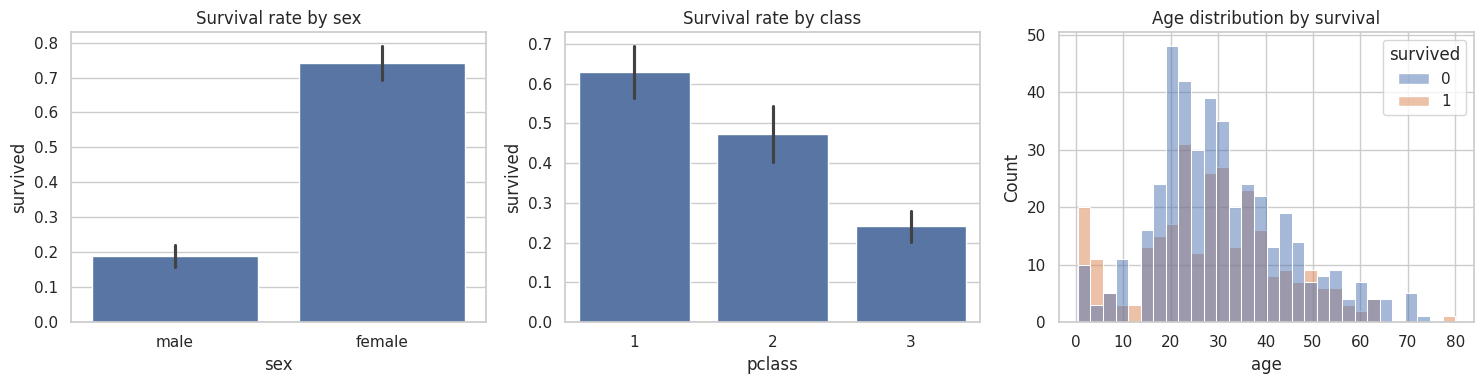

In [5]:
print(f"Overall survival rate: {df['survived'].mean():.1%}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.barplot(data=df, x="sex", y="survived", ax=axes[0])
axes[0].set_title("Survival rate by sex")
sns.barplot(data=df, x="pclass", y="survived", ax=axes[1])
axes[1].set_title("Survival rate by class")
sns.histplot(data=df, x="age", hue="survived", bins=30, ax=axes[2])
axes[2].set_title("Age distribution by survival")
plt.tight_layout()
plt.show()

**Observations:** Women survived at a much higher rate than men, and survival dropped with each lower class. These two features will likely matter most to the model.

## 4. Clean the data

In [6]:
data = df.copy()

# Age: fill with the median age of passengers in the same class and sex.
# (More accurate than one global median, since age differs between groups.)
data["age"] = data.groupby(["pclass", "sex"])["age"].transform(lambda s: s.fillna(s.median()))

# Embarked: only 2 missing, so fill with the most common port
data["embarked"] = data["embarked"].fillna(data["embarked"].mode()[0])

# Deck: too much is missing to be useful, so we won't use it
print("Missing values in the columns we need:")
print(data[["age", "embarked", "fare"]].isnull().sum())

Missing values in the columns we need:
age         0
embarked    0
fare        0
dtype: int64


## 5. Feature engineering

In [7]:
# New feature: total family size aboard (siblings/spouses + parents/children + the passenger)
data["family_size"] = data["sibsp"] + data["parch"] + 1

# Convert text to numbers: sex becomes 0/1, embarked becomes separate 0/1 columns
data["sex"] = (data["sex"] == "female").astype(int)   # 1 = female, 0 = male
data = pd.get_dummies(data, columns=["embarked"], drop_first=True)

features = ["pclass", "sex", "age", "fare", "family_size"] + \
           [c for c in data.columns if c.startswith("embarked_")]
X = data[features].astype(float)
y = data["survived"]
X.head()

,pclass,sex,age,fare,family_size,embarked_Q,embarked_S
0,3.0,0.0,22.0,7.2500,2.0,0.0,1.0
1,1.0,1.0,38.0,71.2833,2.0,0.0,0.0
2,3.0,1.0,26.0,7.9250,1.0,0.0,1.0
3,1.0,1.0,35.0,53.1000,2.0,0.0,1.0
4,3.0,0.0,35.0,8.0500,1.0,0.0,1.0


## 6. Train/test split

In [8]:
# Hold out 20% of the data to test on passengers the model has never seen.
# stratify=y keeps the survived/died ratio the same in both sets.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f"Train: {X_train.shape[0]} rows | Test: {X_test.shape[0]} rows")

Train: 712 rows | Test: 179 rows


## 7. Model 1: Logistic regression (baseline)

In [9]:
log_reg = LogisticRegression(max_iter=1000)
log_reg.fit(X_train, y_train)
lr_pred = log_reg.predict(X_test)

print(f"Logistic regression accuracy: {accuracy_score(y_test, lr_pred):.3f}")
print()
print(classification_report(y_test, lr_pred, target_names=["Died", "Survived"]))

Logistic regression accuracy: 0.810

              precision    recall  f1-score   support

        Died       0.82      0.88      0.85       110
    Survived       0.79      0.70      0.74        69

    accuracy                           0.81       179
   macro avg       0.80      0.79      0.79       179
weighted avg       0.81      0.81      0.81       179



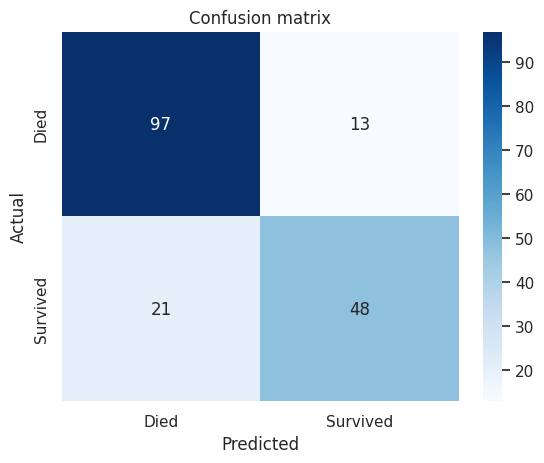

In [10]:
cm = confusion_matrix(y_test, lr_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Died", "Survived"], yticklabels=["Died", "Survived"])
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Confusion matrix")
plt.show()

## 8. Which features matter?

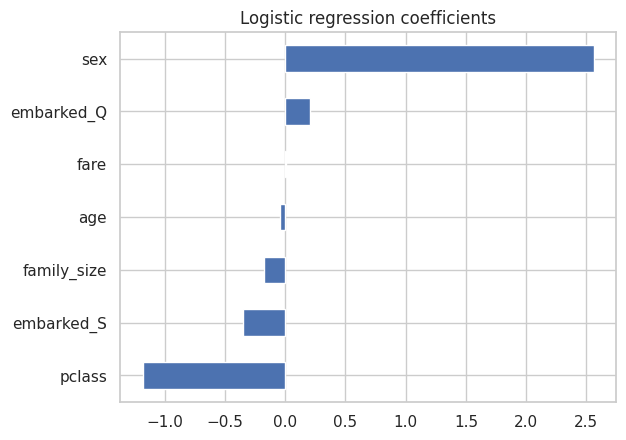

In [11]:
coefs = pd.Series(log_reg.coef_[0], index=features).sort_values()
coefs.plot(kind="barh", title="Logistic regression coefficients")
plt.show()
# Positive = increases survival odds, negative = decreases them

## 9. Model 2: Random forest (comparison)

Logistic regression: 0.810
Random forest:       0.804


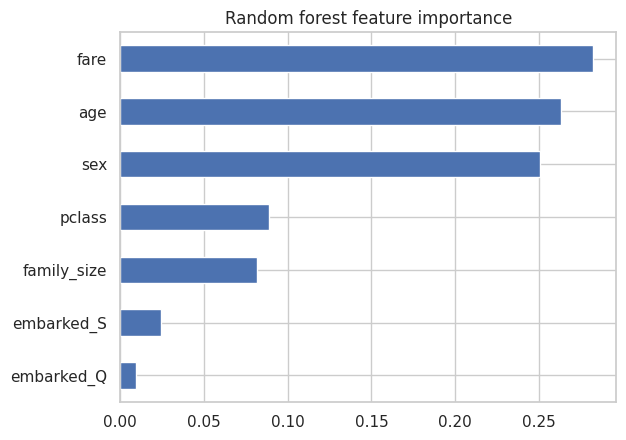

In [12]:
rf = RandomForestClassifier(n_estimators=200, random_state=42)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)

print(f"Logistic regression: {accuracy_score(y_test, lr_pred):.3f}")
print(f"Random forest:       {accuracy_score(y_test, rf_pred):.3f}")

pd.Series(rf.feature_importances_, index=features).sort_values().plot(
    kind="barh", title="Random forest feature importance")
plt.show()

## 10. Conclusions
- Sex and passenger class were the strongest predictors of survival.
- Both models reach roughly 81% accuracy on the test set.
- Limitations: small dataset, only one train/test split, and I estimated missing ages.
- Next steps: try cross-validation and tune the random forest